In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

url = ("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
       "master/data/Telco-Customer-Churn.csv")
df = pd.read_csv(url)
df.to_csv("telco_churn.csv", index=False)     # keep a local copy

print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nMissing values (total):", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nClass balance:")
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True).round(3))

Shape: (7043, 21)

Data types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

Missing values (total): 0
Duplicate rows: 0

Class balance:
Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


In [2]:
from sklearn.model_selection import train_test_split

# 1. Fix TotalCharges (blank text -> number)
print("Blank TotalCharges:", (df["TotalCharges"].str.strip() == "").sum())
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Tenure of those customers:", df.loc[df["TotalCharges"].isnull(), "tenure"].unique())
df["TotalCharges"] = df["TotalCharges"].fillna(0)      # new customers: billed nothing yet

# 2. Drop the ID column and turn the target into 0/1
df = df.drop(columns="customerID")
df["Churn"] = (df["Churn"] == "Yes").astype(int)

# 3. Hold out 20% TEST set NOW - not touched until the final step
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42,
                                     stratify=df["Churn"])

print("\nTrain:", train_df.shape, " churn rate:", round(train_df["Churn"].mean(), 3))
print("Test: ", test_df.shape,  " churn rate:", round(test_df["Churn"].mean(), 3))

Blank TotalCharges: 11
Tenure of those customers: [0]

Train: (5634, 20)  churn rate: 0.265
Test:  (1409, 20)  churn rate: 0.265


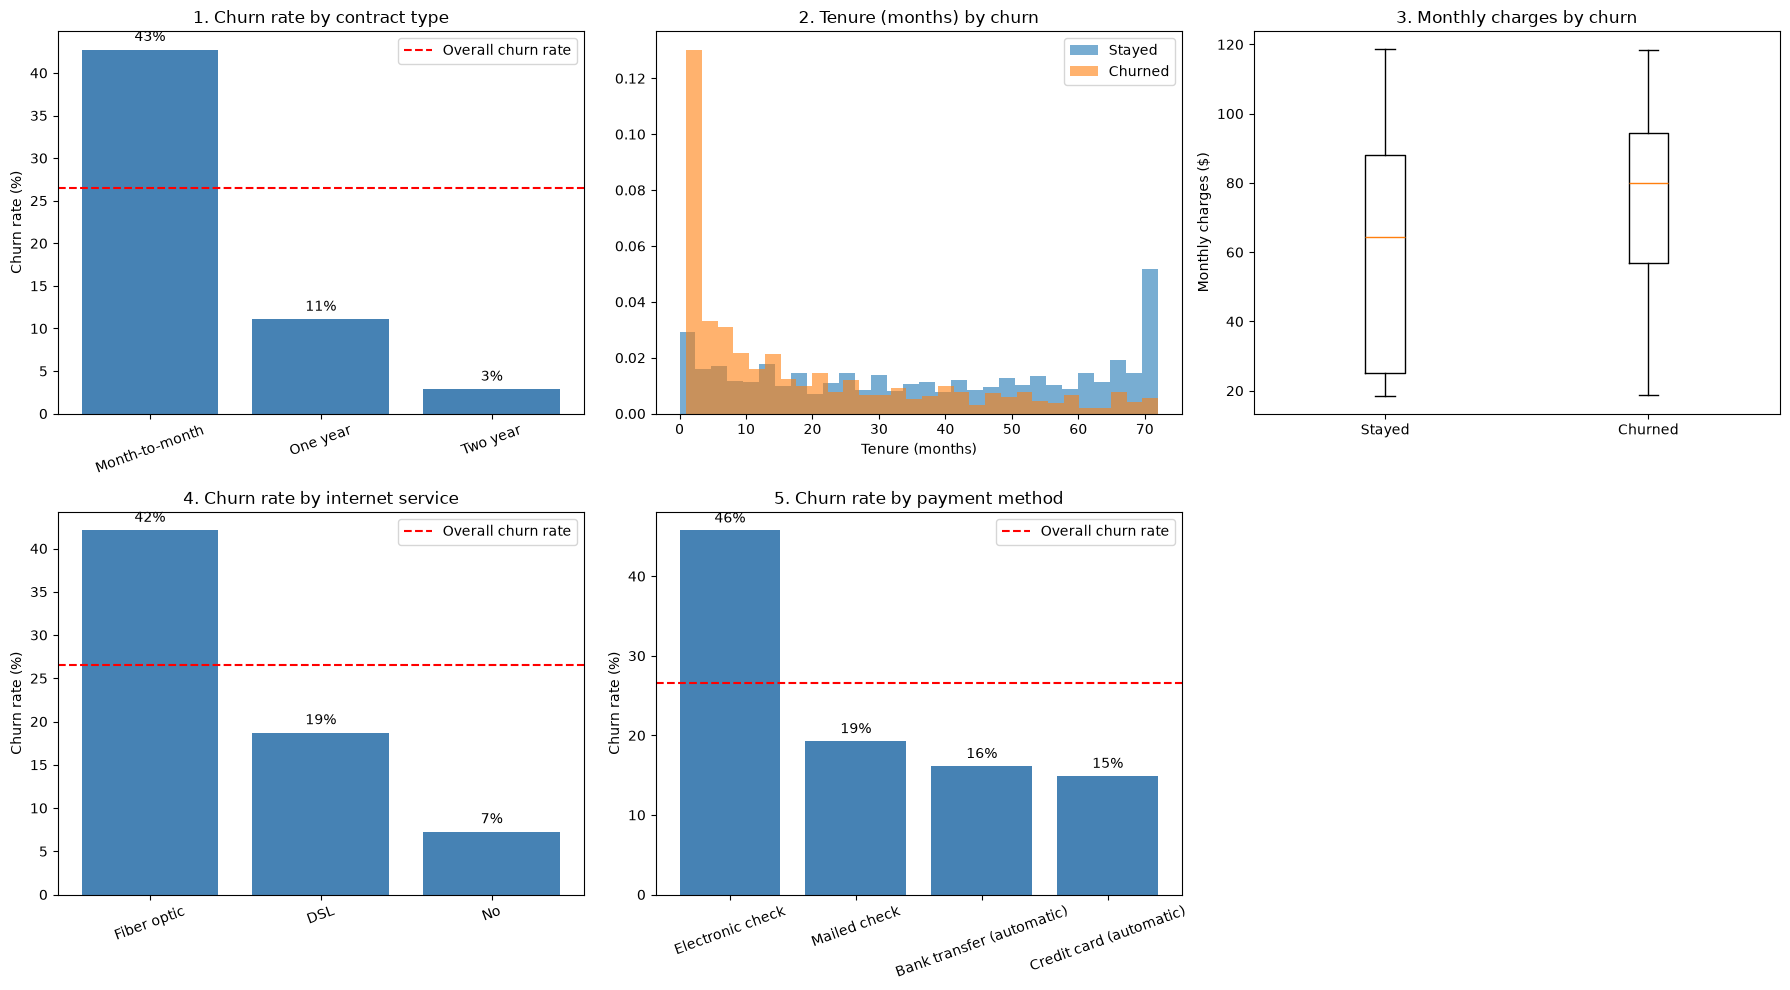

Median tenure  - stayed: 38.0 | churned: 10.0
Median monthly - stayed: 64.4 | churned: 79.95


In [3]:
def churn_rate_bar(ax, col, title):
    rate = train_df.groupby(col)["Churn"].mean().sort_values(ascending=False) * 100
    ax.bar(rate.index, rate.values, color="steelblue")
    ax.axhline(train_df["Churn"].mean() * 100, color="red", linestyle="--",
               label="Overall churn rate")
    for i, v in enumerate(rate.values):
        ax.text(i, v + 1, f"{v:.0f}%", ha="center")
    ax.set_title(title)
    ax.set_ylabel("Churn rate (%)")
    ax.tick_params(axis="x", rotation=20)
    ax.legend()

stay = train_df[train_df["Churn"] == 0]
left = train_df[train_df["Churn"] == 1]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Contract
churn_rate_bar(axes[0, 0], "Contract", "1. Churn rate by contract type")

# 2. Tenure
axes[0, 1].hist(stay["tenure"], bins=30, alpha=0.6, label="Stayed", density=True)
axes[0, 1].hist(left["tenure"], bins=30, alpha=0.6, label="Churned", density=True)
axes[0, 1].set_title("2. Tenure (months) by churn")
axes[0, 1].set_xlabel("Tenure (months)")
axes[0, 1].legend()

# 3. Monthly charges
axes[0, 2].boxplot([stay["MonthlyCharges"], left["MonthlyCharges"]],
                   tick_labels=["Stayed", "Churned"])
axes[0, 2].set_title("3. Monthly charges by churn")
axes[0, 2].set_ylabel("Monthly charges ($)")

# 4. Internet service
churn_rate_bar(axes[1, 0], "InternetService", "4. Churn rate by internet service")

# 5. Payment method
churn_rate_bar(axes[1, 1], "PaymentMethod", "5. Churn rate by payment method")

axes[1, 2].axis("off")     # 6th slot not needed
plt.tight_layout()
plt.savefig("eda_charts.png", dpi=150)
plt.show()

print("Median tenure  - stayed:", stay["tenure"].median(), "| churned:", left["tenure"].median())
print("Median monthly - stayed:", stay["MonthlyCharges"].median(), "| churned:", left["MonthlyCharges"].median())

### EDA findings (training data only)
1. **Contract:** month-to-month customers churn at 43%, vs 11% (one year) and 3% (two year) - the strongest pattern.
2. **Tenure:** churn is concentrated in the first months; long-tenure customers rarely leave.
3. **Monthly charges:** churners pay more (median about $80 vs $65).
4. **Internet service:** fiber optic customers churn at 42%, vs 19% (DSL) and 7% (no internet).
5. **Payment method:** electronic check users churn at 46%, vs 15-19% for other methods.

### Data checks
- 7043 rows, 21 columns, no duplicate rows. Churn rate 26.5% (imbalanced).
- TotalCharges was stored as text: 11 blank values, all for customers with tenure 0. Converted to numbers and filled with 0 (new customers have not been billed yet).
- customerID dropped (an identifier, not a feature).
- 20% test set (1409 rows) held out with stratify before EDA; it will not be used until the final step.

### Assumptions
- The data is a representative snapshot of customers; past patterns will hold for future customers.
- Each row is an independent customer.
- All features are known before a customer churns (no target leakage, unlike a "cancelled_date" column).

### Metric: ROC-AUC (primary), F1 (secondary)
- Churn is imbalanced (26.5%), so accuracy is misleading - predicting "no churn" for everyone already gives 73.5%.
- The retention team will use the model to **rank customers by churn risk** and contact the top ones, with the number contacted set by budget. ROC-AUC measures exactly this ranking ability, independent of any threshold.
- F1 will also be reported to show how well the model's yes/no predictions balance precision and recall at the chosen threshold.

## Task 2: Features and baseline models

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

df = pd.read_csv("telco_churn.csv")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df = df.drop(columns="customerID")
df["Churn"] = (df["Churn"] == "Yes").astype(int)
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42,
                                     stratify=df["Churn"])
print("Train:", train_df.shape, " Test:", test_df.shape)

Train: (5634, 20)  Test: (1409, 20)


In [5]:
service_cols = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

def add_features(d):
    d = d.copy()
    # 1. Tenure bands
    d["tenure_group"] = pd.cut(d["tenure"], bins=[-1, 12, 24, 48, 72],
                               labels=["0-1 yr", "1-2 yr", "2-4 yr", "4-6 yr"]).astype(str)
    # 2. Average actually paid per month (new customers: use current bill)
    d["avg_monthly_spend"] = np.where(d["tenure"] > 0,
                                      d["TotalCharges"] / d["tenure"].clip(lower=1),
                                      d["MonthlyCharges"])
    # 3. Has the bill gone up compared with their average?
    d["charge_increase"] = d["MonthlyCharges"] - d["avg_monthly_spend"]
    # 4. Number of services used
    d["num_services"] = (d[service_cols] == "Yes").sum(axis=1)
    # 5. Automatic payment
    d["auto_payment"] = d["PaymentMethod"].str.contains("automatic").astype(int)
    return d

train_fe = add_features(train_df)
test_fe  = add_features(test_df)     # same formulas, nothing learned from test

new_cols = ["tenure_group", "avg_monthly_spend", "charge_increase", "num_services", "auto_payment"]
print(train_fe[new_cols].head())
print("\nShape:", train_fe.shape)

print("\nChurn rate by tenure group:")
print((train_fe.groupby("tenure_group")["Churn"].mean() * 100).round(1))
print("\nChurn rate by number of services:")
print((train_fe.groupby("num_services")["Churn"].mean() * 100).round(1))
print("\nChurn rate by auto payment (0 = manual, 1 = automatic):")
print((train_fe.groupby("auto_payment")["Churn"].mean() * 100).round(1))

     tenure_group  avg_monthly_spend  charge_increase  num_services  \
3738       2-4 yr          48.618571         0.581429             3   
3151       1-2 yr          76.770000        -1.670000             2   
4860       1-2 yr          45.411538        -4.861538             3   
3867       2-4 yr          73.296154         0.203846             5   
3810       0-1 yr          44.550000         0.000000             1   

      auto_payment  
3738             0  
3151             0  
4860             0  
3867             1  
3810             0  

Shape: (5634, 25)

Churn rate by tenure group:
tenure_group
0-1 yr    47.3
1-2 yr    28.6
2-4 yr    20.2
4-6 yr     9.9
Name: Churn, dtype: float64

Churn rate by number of services:
num_services
0    42.9
1    21.0
2    31.7
3    36.7
4    32.5
5    26.1
6    23.0
7    12.2
8     4.6
Name: Churn, dtype: float64

Churn rate by auto payment (0 = manual, 1 = automatic):
auto_payment
0    35.0
1    15.5
Name: Churn, dtype: float64


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate

X_train = train_fe.drop(columns="Churn")
y_train = train_fe["Churn"]

num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
print("Numeric columns:", len(num_cols), num_cols)
print("Categorical columns:", len(cat_cols))

preprocess = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])

models = {
    "Dummy (majority)":    DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest":       RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
}

rows = []
for name, model in models.items():
    pipe = Pipeline([("preprocess", preprocess), ("model", model)])
    cv = cross_validate(pipe, X_train, y_train, cv=5, scoring=["roc_auc", "f1"])
    rows.append({"Model": name,
                 "CV ROC-AUC": round(cv["test_roc_auc"].mean(), 3),
                 "CV F1":      round(cv["test_f1"].mean(), 3),
                 "F1 std":     round(cv["test_f1"].std(), 3)})

results = pd.DataFrame(rows)
print("\n", results.to_string(index=False))
results.to_csv("baseline_results.csv", index=False)     # saved for the git commit

Numeric columns: 8 ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'avg_monthly_spend', 'charge_increase', 'num_services', 'auto_payment']
Categorical columns: 16

               Model  CV ROC-AUC  CV F1  F1 std
   Dummy (majority)       0.500  0.000   0.000
Logistic Regression       0.846  0.591   0.025
      Random Forest       0.828  0.560   0.032


### New features (5)
| Feature | Definition | Finding (train) |
|---|---|---|
| tenure_group | tenure in bands 0-1, 1-2, 2-4, 4-6 yrs | churn 47.3% → 28.6% → 20.2% → 9.9% |
| avg_monthly_spend | TotalCharges / tenure | average actually paid per month |
| charge_increase | MonthlyCharges - avg_monthly_spend | has the bill gone up recently? |
| num_services | count of services used | how "tied in" the customer is |
| auto_payment | 1 if automatic bank transfer / credit card | manual 35.0% vs automatic 15.5% churn |

All features are calculated from each customer's own row only, so applying them to the test set causes no leakage.

### Baseline results (5-fold CV on training data)
| Model | CV ROC-AUC | CV F1 |
|---|---|---|
| Dummy (majority) | 0.500 | 0.000 |
| Logistic Regression | 0.846 | 0.591 |
| Random Forest | 0.828 | 0.560 |

- Preprocessing (median imputer + scaler for 8 numeric columns; most-frequent imputer + one-hot for 16 categorical columns) runs inside the pipeline, so it is re-fitted in every CV fold - no leakage.
- Logistic Regression is the best baseline: the main churn drivers (contract, tenure, payment method) are close to linear.
- Both models clearly beat the dummy baseline (AUC 0.50). F1 is measured at the default 0.5 threshold and can be improved by threshold tuning in Part 2.

## Part 2: XGBoost, tuning and comparison

In [7]:
from xgboost import XGBClassifier

ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {ratio:.2f}")

models_bal = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest":       RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                  min_samples_leaf=5, random_state=42, n_jobs=-1),
    "XGBoost":             XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                                         scale_pos_weight=ratio, eval_metric="logloss",
                                         random_state=42),
}

rows = []
for name, model in models_bal.items():
    pipe = Pipeline([("preprocess", preprocess), ("model", model)])
    cv = cross_validate(pipe, X_train, y_train, cv=5, scoring=["roc_auc", "f1"])
    rows.append({"Model": name,
                 "CV ROC-AUC": round(cv["test_roc_auc"].mean(), 3),
                 "CV F1":      round(cv["test_f1"].mean(), 3)})

balanced_results = pd.DataFrame(rows)
print(balanced_results.to_string(index=False))

scale_pos_weight = 2.77
              Model  CV ROC-AUC  CV F1
Logistic Regression       0.846  0.627
      Random Forest       0.845  0.632
            XGBoost       0.839  0.626


In [8]:
import time
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint

searches = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, class_weight="balanced"),
        {"model__C": loguniform(0.001, 100)}),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1),
        {"model__n_estimators":     randint(200, 501),
         "model__max_depth":        [None, 5, 8, 12, 16],
         "model__min_samples_leaf": randint(1, 21),
         "model__max_features":     ["sqrt", "log2", 0.5]}),
}

tuned = {}
for name, (model, params) in searches.items():
    pipe = Pipeline([("preprocess", preprocess), ("model", model)])
    search = RandomizedSearchCV(pipe, params, n_iter=20, cv=5, scoring="roc_auc",
                                random_state=42, n_jobs=-1)
    start = time.time()
    search.fit(X_train, y_train)            # TRAIN data only
    tuned[name] = search.best_estimator_
    print(f"{name}: best CV ROC-AUC {search.best_score_:.3f} "
          f"in {time.time() - start:.0f} s")
    print("   best params:", search.best_params_)

Logistic Regression: best CV ROC-AUC 0.846 in 12 s
   best params: {'model__C': np.float64(56.69849511478853)}
Random Forest: best CV ROC-AUC 0.848 in 75 s
   best params: {'model__max_depth': 16, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 17, 'model__n_estimators': 258}


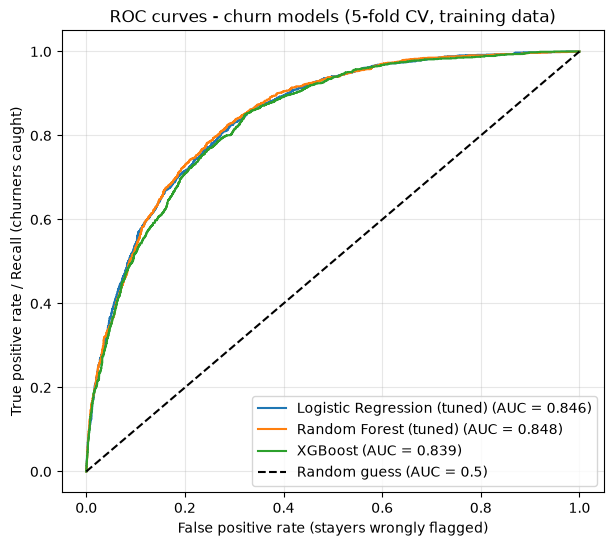

                      Model  ROC-AUC    F1  Precision  Recall
Logistic Regression (tuned)    0.846 0.627      0.518   0.794
      Random Forest (tuned)    0.848 0.632      0.528   0.789
                    XGBoost    0.839 0.625      0.532   0.757


In [9]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (roc_auc_score, roc_curve, f1_score,
                             precision_score, recall_score)

final_models = {
    "Logistic Regression (tuned)": tuned["Logistic Regression"],
    "Random Forest (tuned)":       tuned["Random Forest"],
    "XGBoost":                     Pipeline([("preprocess", preprocess),
                                             ("model", models_bal["XGBoost"])]),
}

oof = {}        # out-of-fold churn probabilities for every training customer
rows = []
plt.figure(figsize=(7, 6))

for name, pipe in final_models.items():
    p = cross_val_predict(pipe, X_train, y_train, cv=5, method="predict_proba")[:, 1]
    oof[name] = p
    pred = (p >= 0.5).astype(int)
    auc = roc_auc_score(y_train, p)
    rows.append({"Model": name,
                 "ROC-AUC":   round(auc, 3),
                 "F1":        round(f1_score(y_train, pred), 3),
                 "Precision": round(precision_score(y_train, pred), 3),
                 "Recall":    round(recall_score(y_train, pred), 3)})
    fpr, tpr, _ = roc_curve(y_train, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.5)")
plt.xlabel("False positive rate (stayers wrongly flagged)")
plt.ylabel("True positive rate / Recall (churners caught)")
plt.title("ROC curves - churn models (5-fold CV, training data)")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("roc_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

comparison = pd.DataFrame(rows)
print(comparison.to_string(index=False))
comparison.to_csv("model_comparison.csv", index=False)

In [10]:
from sklearn.metrics import precision_recall_curve, confusion_matrix

chosen_name = "Random Forest (tuned)"
p = oof[chosen_name]

prec, rec, thr = precision_recall_curve(y_train, p)
prec, rec = prec[:-1], rec[:-1]

ok = rec >= 0.75                                   # business rule: catch at least 75%
best_threshold = thr[np.argmax(np.where(ok, prec, -1))]

pred_t = (p >= best_threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_train, pred_t).ravel()

print(f"Chosen model: {chosen_name}")
print(f"Threshold: {best_threshold:.3f}")
print(f"Recall {recall_score(y_train, pred_t):.3f} | Precision {precision_score(y_train, pred_t):.3f} "
      f"| F1 {f1_score(y_train, pred_t):.3f}")
print(f"\nOut of {len(y_train)} training customers ({y_train.sum()} churners):")
print(f"  Flagged for a call: {pred_t.sum()} ({pred_t.mean()*100:.0f}% of customers)")
print(f"  Churners caught:    {tp} | missed: {fn}")
print(f"  Wasted calls (stayers flagged): {fp}")

Chosen model: Random Forest (tuned)
Threshold: 0.535
Recall 0.751 | Precision 0.550 | F1 0.635

Out of 5634 training customers (1495 churners):
  Flagged for a call: 2039 (36% of customers)
  Churners caught:    1122 | missed: 373
  Wasted calls (stayers flagged): 917


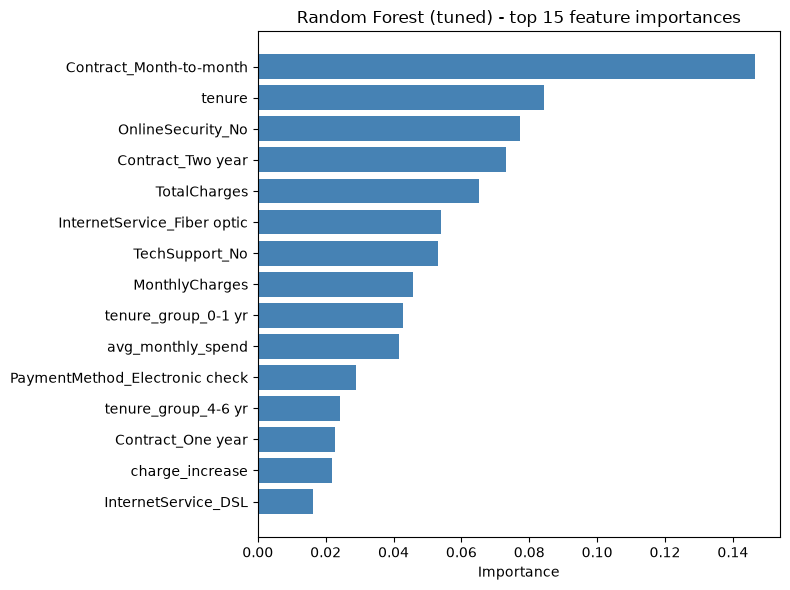

Contract_Month-to-month        0.147
tenure                         0.084
OnlineSecurity_No              0.077
Contract_Two year              0.073
TotalCharges                   0.065
InternetService_Fiber optic    0.054
TechSupport_No                 0.053
MonthlyCharges                 0.046
tenure_group_0-1 yr            0.043
avg_monthly_spend              0.042


In [11]:
best_pipe = tuned["Random Forest"]
names = best_pipe.named_steps["preprocess"].get_feature_names_out()
names = [n.split("__", 1)[1] for n in names]          # drop the "num__" / "cat__" prefix
imp = pd.Series(best_pipe.named_steps["model"].feature_importances_, index=names)
top = imp.sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 6))
plt.barh(top.index[::-1], top.values[::-1], color="steelblue")
plt.xlabel("Importance")
plt.title("Random Forest (tuned) - top 15 feature importances")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150)
plt.show()

print(top.head(10).round(3).to_string())

### Model comparison (5-fold CV on training data, balanced class weights)
| Model | ROC-AUC |
|---|---|
| Logistic Regression (tuned, C≈57) | 0.846 |
| Random Forest (tuned, depth 16, min_samples_leaf 17) | 0.848 |
| XGBoost (scale_pos_weight 2.77) | 0.839 |

Full table with F1, precision and recall: model_comparison.csv. ROC chart: roc_comparison.png.
The three models are effectively tied (within 0.01 AUC). **Chosen model: Random Forest (tuned)** - highest ROC-AUC, and it provides feature importances directly. Logistic Regression is an equally good, simpler alternative.

### Threshold (business rule: catch at least 75% of churners)
Threshold **0.535** → recall 0.751, precision 0.550, F1 0.635 (out-of-fold, training data).
Calling the riskiest 36% of customers reaches 75% of all churners - about twice as many as calling a random 36%.

### Top 5 features in business terms
1. **Month-to-month contract** - no commitment, so leaving costs nothing. These customers churn at 43%. *Action:* offer discounts or perks to move them onto 1- or 2-year contracts.
2. **Tenure** - new customers are most at risk (47% churn in the first year vs 10% after 4 years). *Action:* a strong onboarding programme and check-ins in the first months.
3. **No online security service** - customers without add-on services are less tied in and get less value from the company. *Action:* offer a free trial of security / tech support to at-risk customers.
4. **Two-year contract** - the strongest protective factor: only 3% churn. It confirms point 1 from the other side - commitment keeps customers.
5. **Total charges** - low total charges mostly mean a newer customer (overlaps with tenure); high charges with short tenure can signal price pressure.

Note: importance shows how much a feature matters, not the direction; directions come from the EDA charts. Related features (tenure, TotalCharges, tenure_group) share importance between them.

## Part 2 - Task 2: Final evaluation and predictions

FINAL TEST RESULTS - Random Forest (tuned), threshold 0.535
ROC-AUC:   0.844
F1:        0.638
Precision: 0.547
Recall:    0.767

Confusion matrix [[TN FP] [FN TP]]:
[[797 238]
 [ 87 287]]


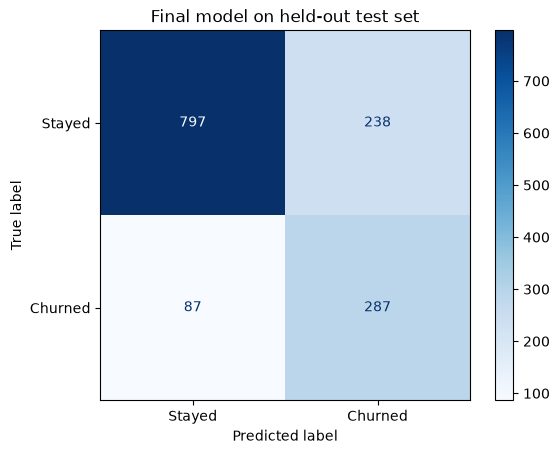

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay

X_test = test_fe.drop(columns="Churn")
y_test = test_fe["Churn"]

test_proba = best_pipe.predict_proba(X_test)[:, 1]          # used ONCE
test_pred  = (test_proba >= best_threshold).astype(int)

print(f"FINAL TEST RESULTS - {chosen_name}, threshold {best_threshold:.3f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, test_proba):.3f}")
print(f"F1:        {f1_score(y_test, test_pred):.3f}")
print(f"Precision: {precision_score(y_test, test_pred):.3f}")
print(f"Recall:    {recall_score(y_test, test_pred):.3f}")

cm = confusion_matrix(y_test, test_pred)
print("\nConfusion matrix [[TN FP] [FN TP]]:")
print(cm)

ConfusionMatrixDisplay(cm, display_labels=["Stayed", "Churned"]).plot(cmap="Blues")
plt.title("Final model on held-out test set")
plt.savefig("test_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
import joblib

joblib.dump({"model": best_pipe, "threshold": float(best_threshold)}, "churn_model.joblib")
print("Saved churn_model.joblib")

raw = pd.read_csv("telco_churn.csv")
new_customers = raw.loc[test_df.index[:20]].drop(columns="Churn")
new_customers.to_csv("new_customers.csv", index=False)
print("Saved new_customers.csv:", new_customers.shape)

Saved churn_model.joblib
Saved new_customers.csv: (20, 20)


In [14]:
%%writefile predict_new.py
"""Predict churn for new customers.
Usage:  python predict_new.py new_customers.csv predictions.csv
"""
import sys
import joblib
import numpy as np
import pandas as pd

SERVICE_COLS = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]


def add_features(d):
    """Same 5 features as in training."""
    d = d.copy()
    d["tenure_group"] = pd.cut(d["tenure"], bins=[-1, 12, 24, 48, 72],
                               labels=["0-1 yr", "1-2 yr", "2-4 yr", "4-6 yr"]).astype(str)
    d["avg_monthly_spend"] = np.where(d["tenure"] > 0,
                                      d["TotalCharges"] / d["tenure"].clip(lower=1),
                                      d["MonthlyCharges"])
    d["charge_increase"] = d["MonthlyCharges"] - d["avg_monthly_spend"]
    d["num_services"] = (d[SERVICE_COLS] == "Yes").sum(axis=1)
    d["auto_payment"] = d["PaymentMethod"].str.contains("automatic").astype(int)
    return d


def prepare(raw):
    """Clean raw data exactly as in training."""
    d = raw.copy()
    d["TotalCharges"] = pd.to_numeric(d["TotalCharges"], errors="coerce").fillna(0)
    ids = d["customerID"] if "customerID" in d.columns else pd.Series(range(len(d)))
    d = d.drop(columns=["customerID", "Churn"], errors="ignore")
    return ids, add_features(d)


def main():
    in_path = sys.argv[1] if len(sys.argv) > 1 else "new_customers.csv"
    out_path = sys.argv[2] if len(sys.argv) > 2 else "predictions.csv"

    saved = joblib.load("churn_model.joblib")
    model, threshold = saved["model"], saved["threshold"]

    ids, X = prepare(pd.read_csv(in_path))
    proba = model.predict_proba(X)[:, 1]

    out = pd.DataFrame({"customerID": ids.values,
                        "churn_probability": proba.round(3),
                        "predicted_churn": (proba >= threshold).astype(int)})
    out["action"] = np.where(out["predicted_churn"] == 1,
                             "Call - retention offer", "No action")
    out = out.sort_values("churn_probability", ascending=False)
    out.to_csv(out_path, index=False)

    print(f"Scored {len(out)} customers with threshold {threshold:.3f}")
    print(f"Flagged for a call: {out['predicted_churn'].sum()}")
    print(f"Saved {out_path}")


if __name__ == "__main__":
    main()

Writing predict_new.py


In [15]:
t_auc  = roc_auc_score(y_test, test_proba)
t_f1   = f1_score(y_test, test_pred)
t_prec = precision_score(y_test, test_pred)
t_rec  = recall_score(y_test, test_pred)
tn, fp, fn, tp = confusion_matrix(y_test, test_pred).ravel()

report = f"""# Customer Churn Prediction - Project Report

## 1. Problem
A telecom company loses about 26.5% of its customers. The goal is to predict which customers
are likely to churn, so the retention team can contact them with an offer before they leave.

## 2. Data
- Telco Customer Churn dataset: 7,043 customers, 21 columns (contract, tenure, services, charges, payment).
- Data issue found: `TotalCharges` stored as text with 11 blank values (all new customers, tenure 0) - converted and set to 0.
- 20% test set (1,409 customers) held out with stratification before any analysis and used once at the end.

## 3. Method
- EDA on training data: churn is highest for month-to-month contracts (43%), first-year customers (47%),
  fiber optic users (42%) and electronic-check payers (46%).
- 5 new features: tenure group, average monthly spend, charge increase, number of services, automatic payment.
- One Pipeline (imputation, scaling, one-hot encoding, model) so preprocessing is fitted only on training folds - no leakage.
- Compared Logistic Regression, Random Forest and XGBoost with 5-fold CV, class weights for the imbalance,
  and RandomizedSearchCV tuning (scoring = ROC-AUC). All three tied within 0.01 AUC; **Random Forest (tuned)** chosen
  (CV ROC-AUC 0.848).
- Metric: ROC-AUC, because the business ranks customers by risk; F1 also reported.
- Threshold {best_threshold:.3f} chosen to catch at least 75% of churners with the fewest calls.

## 4. Results (held-out test set, used once)
| ROC-AUC | F1 | Precision | Recall |
|---|---|---|---|
| {t_auc:.3f} | {t_f1:.3f} | {t_prec:.3f} | {t_rec:.3f} |

- Caught {tp} of {tp + fn} churners; missed {fn}. {fp} calls went to customers who would have stayed.
- Calling the riskiest {(tp + fp) / len(y_test) * 100:.0f}% of customers reaches {t_rec * 100:.0f}% of churners -
  about twice as many as calling the same number of random customers.
- Test results match cross-validation, so the model is not overfitted.

## 5. Limitations
- Single historical snapshot; customer behaviour and prices may change, so the model needs monitoring and retraining.
- About 45% of flagged customers would not have churned - offers to them have a cost.
- Feature importance shows which factors matter, not proof that they cause churn.
- No data on customer complaints, service quality or competitor offers, which likely drive churn too.

## 6. Recommendations
1. Move month-to-month customers to 1- or 2-year contracts with a discount or perk (2-year churn is only 3%).
2. Strengthen onboarding and check-ins in the first 12 months, when churn risk is highest.
3. Offer free trials of online security / tech support - customers without them churn more.
4. Encourage automatic payment (manual payers churn about twice as often).
5. Run `predict_new.py` monthly on the active customer list and give the call list to the retention team;
   adjust the threshold to match the team's call capacity.
"""

with open("REPORT.md", "w", encoding="utf-8") as f:
    f.write(report)
print(report)

# Customer Churn Prediction - Project Report

## 1. Problem
A telecom company loses about 26.5% of its customers. The goal is to predict which customers
are likely to churn, so the retention team can contact them with an offer before they leave.

## 2. Data
- Telco Customer Churn dataset: 7,043 customers, 21 columns (contract, tenure, services, charges, payment).
- Data issue found: `TotalCharges` stored as text with 11 blank values (all new customers, tenure 0) - converted and set to 0.
- 20% test set (1,409 customers) held out with stratification before any analysis and used once at the end.

## 3. Method
- EDA on training data: churn is highest for month-to-month contracts (43%), first-year customers (47%),
  fiber optic users (42%) and electronic-check payers (46%).
- 5 new features: tenure group, average monthly spend, charge increase, number of services, automatic payment.
- One Pipeline (imputation, scaling, one-hot encoding, model) so preprocessing is fitted only on training fo